# Transformer-CNN Hybride (Conformer/AST-inspired) — PCG

Ce notebook implémente une architecture **hybride Transformer-CNN** pour la
classification des sons cardiaques (normal / abnormal) à partir de spectrogrammes Mel.

- **CNN** : extrait des caractéristiques locales temps-fréquence du Mel-spectrogramme.
- **Transformer Encoder** : capture les dépendances temporelles longue portée, notamment
  la structure des phases cardiaques **B1 (S1)** et **B2 (S2)** dans le temps.
- **Validation** : même **Stratified 3-Fold Cross-Validation** au niveau enregistrement
  que les notebooks précédents (`build_3fold_recording_splits`, `KFold(3, shuffle=True, random_state=10)`).
- **MLflow** : paramètres, métriques par pli, Mean ± Std, artefacts et modèle dans `tp3_audio_engine`.
- **Métriques** : Accuracy, Precision, Recall, F1-score, AUC, balanced accuracy, matrices de confusion.
- **Courbes** : Loss et Accuracy par pli.


## 1. Imports et configuration

In [1]:
import gc
import json
import os
import random
import sys
import time
from datetime import datetime
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("XLA_FLAGS", "--xla_gpu_strict_conv_algorithm_picker=false")

DATA_ROOT = next((p / "ourdataset" / "train" for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "ourdataset" / "train").is_dir()), None)
assert DATA_ROOT is not None, f"ourdataset/train introuvable depuis {Path.cwd()}"
AUDIO_ENGINE_DIR = DATA_ROOT.parent.parent / "audio_engine"
sys.path.insert(0, str(AUDIO_ENGINE_DIR))

import librosa
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score, roc_curve)

from preprocess import AudioError, Preprocessor
from fold_utils import (build_3fold_recording_splits, plot_all_folds_training,
                        plot_training_history, save_history_csv)
from src.dataset import KerasMelSequence

MODEL_DIR = AUDIO_ENGINE_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)
PLOT_DIR = MODEL_DIR / "plots"
PLOT_DIR.mkdir(exist_ok=True)

SR, N_MELS, N_FFT, HOP, T = 2000, 128, 512, 128, 256
DOWN = 2
INPUT_H, INPUT_W = N_MELS // DOWN, T // DOWN  # 64 x 128
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.backend.set_floatx("float32")


def configure_tensorflow_gpu():
    gpus = tf.config.list_physical_devices("GPU")
    if gpus:
        for gpu in gpus:
            try:
                tf.config.experimental.set_memory_growth(gpu, True)
            except Exception as exc:
                print(f"  mémoire dynamique indisponible pour {gpu}: {exc}")
        try:
            tf.config.set_visible_devices(gpus, "GPU")
        except Exception:
            pass
    build = {}
    try:
        build = tf.sysconfig.get_build_info()
    except Exception:
        pass
    cuda_build = build.get("is_cuda_build", build.get("cuda_version") is not None)
    print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
    print("Build CUDA :", cuda_build, "| CUDA", build.get("cuda_version"), "| cuDNN", build.get("cudnn_version"))
    if gpus:
        logical = tf.config.list_logical_devices("GPU") if hasattr(tf.config, 'list_logical_devices') else gpus
        try:
            keras.mixed_precision.set_global_policy("mixed_float16")
            print("Mixed precision: mixed_float16")
        except Exception as exc:
            print("Mixed precision non activée:", exc)
        print("GPU détecté(s) :", [d.name for d in logical], "-> entraînement sur GPU")
    else:
        print("GPU : aucun détecté -> entraînement sur CPU")


configure_tensorflow_gpu()

MEL_CACHE = MODEL_DIR / "tp3_cnn_mels_64x128.npy"
INDEX_CACHE = MODEL_DIR / "tp3_cnn_mels_index.npz"
pre = Preprocessor({"max_segments": 10})


def mel(seg):
    m = librosa.feature.melspectrogram(y=seg, sr=SR, n_fft=N_FFT, hop_length=HOP,
                                       n_mels=N_MELS, fmin=20, fmax=SR // 2)
    m = librosa.power_to_db(m, ref=np.max)
    m = np.pad(m, ((0, 0), (0, max(0, T - m.shape[1]))))[:, :T].astype(np.float32)
    m = (m - m.mean()) / (m.std() + 1e-6)
    return m[::DOWN, ::DOWN]


TensorFlow 2.20.0 | Keras 3.12.4
Build CUDA : True | CUDA 12.5.1 | cuDNN 9
Mixed precision: mixed_float16
GPU détecté(s) : ['/device:GPU:0'] -> entraînement sur GPU


I0000 00:00:1795447442.626902    1103 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


## 2. Cache Mel et splits (identiques aux notebooks précédents)

In [2]:
files = [(p, label) for label, name in enumerate(["normal", "abnormal"])
         for p in sorted((DATA_ROOT / name).glob("*.wav"))]


def build_mel_cache(force=False):
    if MEL_CACHE.exists() and INDEX_CACHE.exists() and not force:
        index = np.load(INDEX_CACHE, allow_pickle=True)
        X = np.load(MEL_CACHE, mmap_mode="r")
        print(f"Cache réutilisé : {MEL_CACHE.name} {X.shape} ({X.nbytes / 1e9:.2f} Go)")
        return X, index["keys"], index["y"].astype(np.int64)

    t0, keys, labels, blocks = time.time(), [], [], []
    for n, (path, label) in enumerate(files, start=1):
        try:
            segments = pre.segment(pre.load_clean(path.read_bytes()))
        except AudioError as error:
            print(f"  ignoré {path.name}: {error}")
            continue
        blocks.append(np.stack([mel(s) for s in segments]).astype(np.float16))
        keys += [f"{label}/{path.name}"] * len(segments)
        labels += [label] * len(segments)
        if n % 500 == 0:
            print(f"  {n}/{len(files)} fichiers, {sum(len(b) for b in blocks)} segments")

    X_all = np.concatenate(blocks).astype(np.float16)[:, None, :, :]
    keys_all = np.array(keys, dtype=object)
    y_all = np.array(labels, dtype=np.int64)
    np.save(MEL_CACHE, X_all)
    np.savez(INDEX_CACHE, keys=keys_all, y=y_all)
    print(f"Cache écrit : {MEL_CACHE.name} en {(time.time()-t0)/60:.1f} min")
    return X_all, keys_all, y_all


X_mel, keys_all, y_all = build_mel_cache()
print(f"{len(y_all)} segments | {len(np.unique(keys_all))} enregistrements | abnormal={y_all.mean():.1%}")

folds, recording_keys = build_3fold_recording_splits(keys_all, n_splits=3, seed=10)
for fold in folds:
    pos_tr, pos_va = fold["train_pos"], fold["test_pos"]
    print(f"pli {fold['fold']}: train={len(pos_tr)} val={len(pos_va)} segments")


Cache réutilisé : tp3_cnn_mels_64x128.npy (22126, 1, 64, 128) (0.36 Go)
22126 segments | 3781 enregistrements | abnormal=23.3%
pli 1: train=14740 val=7386 segments
pli 2: train=14962 val=7164 segments
pli 3: train=14550 val=7576 segments


## 3. Architecture hybride Transformer-CNN

### Principe
1. **Front-end CNN** : convolutions 2D sur le Mel (temps × fréquence) pour extraire
   des motifs locaux (harmoniques, transitoires). Le pooling est appliqué principalement
   sur l'axe fréquence afin de **préserver la résolution temporelle**.
2. **Projection temporelle** : les cartes CNN sont réorganisées en séquence temporelle
   `(batch, time_steps, features)`.
3. **Positional encoding + Transformer Encoder** : l'attention multi-têtes modélise
   les dépendances entre instants éloignés, ce qui permet de capturer la structure
   temporelle des bruits cardiaques, notamment les phases **B1** et **B2**.
4. **Tête de classification** : pooling temporel + MLP + softmax.


In [3]:
@keras.utils.register_keras_serializable(package="hybrid")
class PositionalEncoding(layers.Layer):
    """Encodage positionnel sinusoïdal ajouté à la séquence temporelle."""
    def __init__(self, max_len=256, d_model=128, **kwargs):
        super().__init__(**kwargs)
        self.max_len = max_len
        self.d_model = d_model

    def build(self, input_shape):
        pos = np.arange(self.max_len)[:, np.newaxis]
        i = np.arange(self.d_model)[np.newaxis, :]
        angle_rates = 1 / np.power(10000, (2 * (i // 2)) / np.float32(self.d_model))
        angles = pos * angle_rates
        pe = np.zeros((self.max_len, self.d_model), dtype=np.float32)
        pe[:, 0::2] = np.sin(angles[:, 0::2])
        pe[:, 1::2] = np.cos(angles[:, 1::2])
        self.pe = tf.constant(pe[np.newaxis, :, :], dtype=tf.float32)
        super().build(input_shape)

    def call(self, x):
        seq_len = tf.shape(x)[1]
        # `x` peut être en float16 (mixed precision) : on caste l'encodage sur son dtype.
        pe = tf.cast(self.pe[:, :seq_len, :], x.dtype)
        return x + pe

    def get_config(self):
        """Sérialise les paramètres de la couche (indispensable au rechargement)."""
        config = super().get_config()
        config.update({"max_len": int(self.max_len), "d_model": int(self.d_model)})
        return config


def transformer_encoder_block(x, d_model, num_heads, ff_dim, dropout=0.1, name="enc"):
    # Multi-head self-attention
    attn_out = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model // num_heads,
                                         dropout=dropout, name=f"{name}_mha")(x, x)
    attn_out = layers.Dropout(dropout, name=f"{name}_attn_drop")(attn_out)
    x = layers.LayerNormalization(epsilon=1e-6, name=f"{name}_ln1")(x + attn_out)
    # Feed-forward
    ff = layers.Dense(ff_dim, activation="relu", name=f"{name}_ff1")(x)
    ff = layers.Dropout(dropout, name=f"{name}_ff_drop")(ff)
    ff = layers.Dense(d_model, name=f"{name}_ff2")(ff)
    x = layers.LayerNormalization(epsilon=1e-6, name=f"{name}_ln2")(x + ff)
    return x


def build_transformer_cnn(n_classes=2, input_shape=(64, 128, 1), d_model=128,
                          num_heads=4, ff_dim=256, num_layers=2, dropout=0.2):
    """Hybride CNN + Transformer Encoder.

    Le CNN extrait des features locales; le Transformer modélise la structure
    temporelle globale (B1/B2) via self-attention sur l'axe temporel.
    """
    inputs = keras.Input(shape=input_shape, name="mel_input")

    # --- CNN front-end (pooling surtout en fréquence pour garder le temps) ---
    x = layers.Conv2D(32, 3, padding="same", use_bias=False, name="cnn1_conv")(inputs)
    x = layers.BatchNormalization(name="cnn1_bn")(x)
    x = layers.ReLU(name="cnn1_relu")(x)
    x = layers.MaxPooling2D(pool_size=(2, 2), name="cnn1_pool")(x)  # 32x64

    x = layers.Conv2D(64, 3, padding="same", use_bias=False, name="cnn2_conv")(x)
    x = layers.BatchNormalization(name="cnn2_bn")(x)
    x = layers.ReLU(name="cnn2_relu")(x)
    x = layers.MaxPooling2D(pool_size=(2, 1), name="cnn2_pool")(x)  # 16x64 (temps préservé)

    x = layers.Conv2D(128, 3, padding="same", use_bias=False, name="cnn3_conv")(x)
    x = layers.BatchNormalization(name="cnn3_bn")(x)
    x = layers.ReLU(name="cnn3_relu")(x)
    x = layers.MaxPooling2D(pool_size=(2, 1), name="cnn3_pool")(x)  # 8x64

    # --- Séquence temporelle: (B, freq, time, C) -> (B, time, freq*C) ---
    shape = x.shape  # (None, 8, 64, 128)
    freq_bins = shape[1]
    time_steps = shape[2]
    channels = shape[3]
    x = layers.Permute((2, 1, 3), name="to_time_first")(x)  # (B, time, freq, C)
    x = layers.Reshape((time_steps, freq_bins * channels), name="flatten_freq")(x)
    x = layers.Dense(d_model, name="token_projection")(x)

    # --- Transformer Encoder ---
    x = PositionalEncoding(max_len=time_steps, d_model=d_model, name="pos_encoding")(x)
    x = layers.Dropout(dropout, name="pos_dropout")(x)
    for i in range(num_layers):
        x = transformer_encoder_block(x, d_model=d_model, num_heads=num_heads,
                                      ff_dim=ff_dim, dropout=dropout, name=f"enc{i+1}")

    # --- Classification ---
    x = layers.GlobalAveragePooling1D(name="temporal_gap")(x)
    x = layers.Dense(128, activation="relu", name="head_dense")(x)
    x = layers.Dropout(dropout, name="head_dropout")(x)
    outputs = layers.Dense(n_classes, activation="softmax", dtype="float32", name="classifier")(x)

    model = keras.Model(inputs, outputs, name="transformer_cnn_hybrid")
    return model


model_preview = build_transformer_cnn(n_classes=2, input_shape=(INPUT_H, INPUT_W, 1))
model_preview.summary()
print(f"Paramètres: {model_preview.count_params():,}".replace(",", " "))

Model: "transformer_cnn_hybrid"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ mel_input           │ (None, 64, 128,   │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn1_conv (Conv2D)  │ (None, 64, 128,   │        288 │ mel_input[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn1_bn             │ (None, 64, 128,   │        128 │ cnn1_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn1_relu (ReLU)    │ (None, 64, 128,   │          0 │ cnn1_bn[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn1_pool           │ (None, 32, 64,    │          0 │ cnn1_relu[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn2_conv (Conv2D)  │ (None, 32, 64,    │     18,432 │ cnn1_pool[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn2_bn             │ (None, 32, 64,    │        256 │ cnn2_conv[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn2_relu (ReLU)    │ (None, 32, 64,    │          0 │ cnn2_bn[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn2_pool           │ (None, 16, 64,    │          0 │ cnn2_relu[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn3_conv (Conv2D)  │ (None, 16, 64,    │     73,728 │ cnn2_pool[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn3_bn             │ (None, 16, 64,    │        512 │ cnn3_conv[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn3_relu (ReLU)    │ (None, 16, 64,    │          0 │ cnn3_bn[0][0]     │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn3_pool           │ (None, 8, 64,     │          0 │ cnn3_relu[0][0]   │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ to_time_first       │ (None, 64, 8,     │          0 │ cnn3_pool[0][0]   │
│ (Permute)           │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_freq        │ (None, 64, 1024)  │          0 │ to_time_first[0]… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_projection    │ (None, 64, 128)   │    131,200 │ flatten_freq[0][… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pos_encoding        │ (None, 64, 128)   │          0 │ token_projection

 Total params: 506,274 (1.93 MB)

 Trainable params: 505,826 (1.93 MB)

 Non-trainable params: 448 (1.75 KB)

Paramètres: 506 274


## 4. Helpers (métriques, seuil, AUC callback)

In [4]:
class ValidationAUC(keras.callbacks.Callback):
    def __init__(self, val_seq):
        super().__init__()
        self.val_seq = val_seq
        self.y_true = val_seq.labels[val_seq.indices]

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        proba = self.model.predict(self.val_seq, verbose=0)[:, 1]
        logs["val_auc"] = float(roc_auc_score(self.y_true, proba))


def select_threshold(y_true, proba, min_spec=0.80):
    fpr, tpr, thr = roc_curve(y_true, proba, drop_intermediate=False)
    ok = np.isfinite(thr) & (thr <= 1) & ((1 - fpr) >= min_spec)
    if ok.any():
        indices = np.where(ok)[0]
        return float(thr[indices[np.argmax(tpr[indices])]])
    return 0.5


def classification_metrics(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "accuracy": float(accuracy_score(y_true, pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, pred)),
        "macro_precision": float(precision_score(y_true, pred, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y_true, pred, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, pred, average="macro", zero_division=0)),
        "precision": float(precision_score(y_true, pred, zero_division=0)),
        "recall": float(recall_score(y_true, pred, zero_division=0)),
        "specificity": float(tn / (tn + fp)) if (tn + fp) else float("nan"),
        "f1": float(f1_score(y_true, pred, zero_division=0)),
        "auc": float(roc_auc_score(y_true, proba)),
        "threshold": float(threshold),
        "confusion": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    }


## 5. Entraînement 3-fold (Stratified, recording-level)

In [5]:
EPOCHS = 15
BS = 32  # réduire à 16 si OOM GPU
PATIENCE = 4
LR = 1e-3
D_MODEL = 128
N_HEADS = 4
FF_DIM = 256
N_LAYERS = 2
DROPOUT = 0.2

histories, fold_rows, fold_outputs, fold_models = [], [], [], {}


def run_fold(fold):
    k = fold["fold"]
    pos_tr, pos_va = fold["train_pos"], fold["test_pos"]
    print("=" * 78)
    print(f"PLI {k}/3 | train={len(pos_tr)} | val={len(pos_va)}")

    train_seq = KerasMelSequence(X_mel, y_all, pos_tr, batch_size=BS, shuffle=True, augment=True, seed=SEED + k)
    val_seq = KerasMelSequence(X_mel, y_all, pos_va, batch_size=BS, shuffle=False, augment=False, seed=SEED + k)

    counts = np.bincount(y_all[pos_tr], minlength=2)
    class_weight = {i: float(len(pos_tr) / (2 * counts[i])) for i in range(2) if counts[i] > 0}

    keras.backend.clear_session()
    tf.random.set_seed(SEED + k)
    model = build_transformer_cnn(n_classes=2, input_shape=(INPUT_H, INPUT_W, 1),
                                  d_model=D_MODEL, num_heads=N_HEADS, ff_dim=FF_DIM,
                                  num_layers=N_LAYERS, dropout=DROPOUT)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LR),
                  loss=keras.losses.SparseCategoricalCrossentropy(),
                  metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")])

    callbacks = [
        ValidationAUC(val_seq),
        keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=PATIENCE,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    ]

    history = model.fit(train_seq, validation_data=val_seq, epochs=EPOCHS,
                        class_weight=class_weight, callbacks=callbacks, verbose=2)

    hist = {name: [float(v) for v in values] for name, values in history.history.items()}
    proba = model.predict(val_seq, verbose=0)[:, 1]
    y_true = y_all[pos_va]
    m = classification_metrics(y_true, proba, threshold=0.5)

    plot_training_history(hist, k, PLOT_DIR, "hybrid_transformer_cnn")
    save_history_csv(hist, MODEL_DIR / f"hybrid_fold{k}_history.csv")
    fold_model_path = MODEL_DIR / f"hybrid_fold{k}.keras"
    model.save(fold_model_path)

    row = {
        "fold": k, "epochs_run": len(hist["loss"]),
        "best_epoch": int(np.argmax(hist.get("val_auc", hist["val_loss"]))) + 1,
        "accuracy": m["accuracy"], "balanced_accuracy": m["balanced_accuracy"],
        "precision": m["precision"], "recall": m["recall"], "f1": m["f1"],
        "macro_precision": m["macro_precision"], "macro_recall": m["macro_recall"],
        "macro_f1": m["macro_f1"], "roc_auc": m["auc"], "specificity": m["specificity"],
        "confusion": m["confusion"],
    }
    fold_rows.append(row)
    fold_outputs.append({"fold": k, "y_true": y_true, "proba": proba, "y_pred": (proba >= 0.5).astype(int)})
    histories.append({"fold": k, "steps": list(range(1, len(hist["loss"]) + 1)), "metrics": hist})
    fold_models[k] = {"path": str(fold_model_path), "auc": m["auc"]}
    print(f"pli {k}: Acc={m['accuracy']:.3f} P={m['precision']:.3f} R={m['recall']:.3f} F1={m['f1']:.3f} AUC={m['auc']:.3f}")

    # Libère la mémoire du pli avant le suivant
    del model
    keras.backend.clear_session()
    gc.collect()
    return row


for fold in folds:
    run_fold(fold)

PLI 1/3 | train=14740 | val=7386
Epoch 1/15


I0000 00:00:1795447478.309608    1314 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


461/461 - 133s - 289ms/step - accuracy: 0.4322 - loss: 0.7024 - val_accuracy: 0.2310 - val_loss: 0.7042 - val_auc: 0.6852 - learning_rate: 0.0010
Epoch 2/15
461/461 - 18s - 38ms/step - accuracy: 0.5081 - loss: 0.6933 - val_accuracy: 0.7690 - val_loss: 0.6909 - val_auc: 0.5129 - learning_rate: 0.0010
Epoch 3/15
461/461 - 18s - 38ms/step - accuracy: 0.5784 - loss: 0.6933 - val_accuracy: 0.2310 - val_loss: 0.6942 - val_auc: 0.8522 - learning_rate: 0.0010
Epoch 4/15

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
461/461 - 17s - 37ms/step - accuracy: 0.4356 - loss: 0.6932 - val_accuracy: 0.2310 - val_loss: 0.6947 - val_auc: 0.5000 - learning_rate: 0.0010
Epoch 5/15
461/461 - 17s - 38ms/step - accuracy: 0.3702 - loss: 0.6932 - val_accuracy: 0.7690 - val_loss: 0.6930 - val_auc: 0.5000 - learning_rate: 5.0000e-04
Epoch 6/15

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
461/461 - 18s - 39ms/step - accuracy: 0.5853 - loss: 0.6932 - val

## 6. Courbes d'entraînement et matrices de confusion

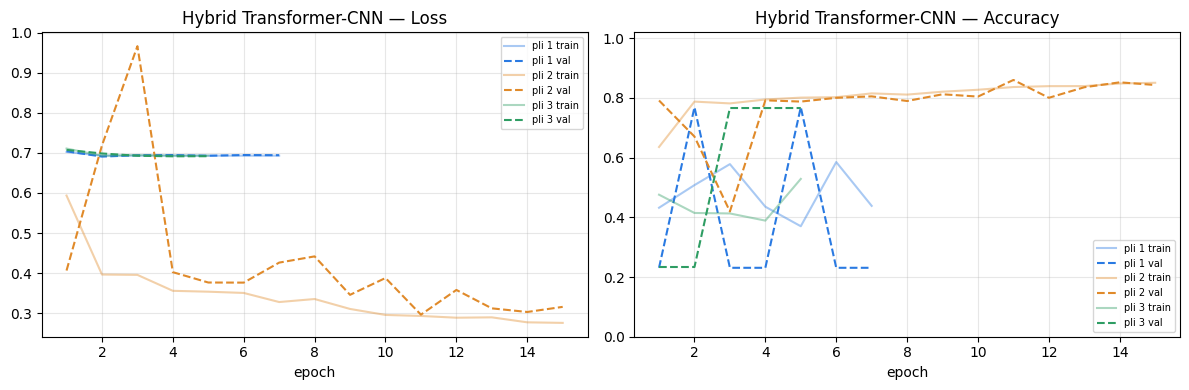

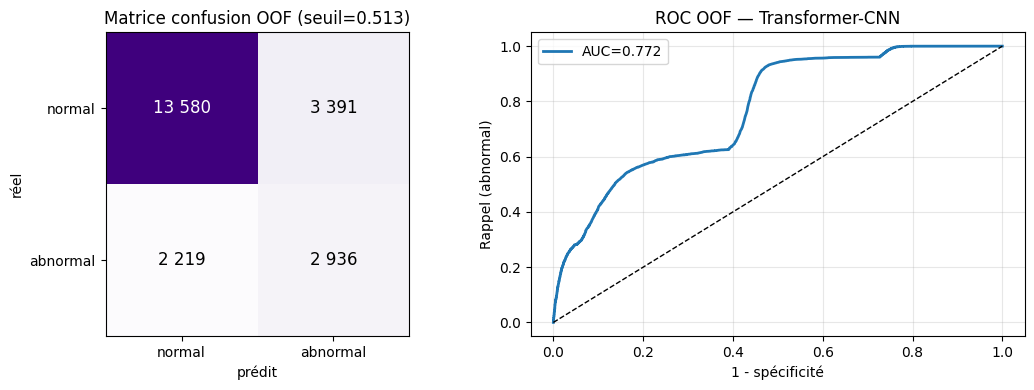

Seuil OOF=0.5134 | Acc=0.746 P=0.464 R=0.570 F1=0.511 AUC=0.772


In [9]:
HYBRID_CURVES_PLOT = plot_all_folds_training(histories, PLOT_DIR, "hybrid_transformer_cnn")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
palette = ["#2a7ae2", "#e08a2a", "#2e9d63"]
for i, entry in enumerate(histories):
    h = entry["metrics"]
    epochs = np.arange(1, len(h["loss"]) + 1)
    c = palette[i % len(palette)]
    axes[0].plot(epochs, h["loss"], color=c, alpha=0.4, label=f"pli {entry['fold']} train")
    axes[0].plot(epochs, h["val_loss"], color=c, linestyle="--", label=f"pli {entry['fold']} val")
    axes[1].plot(epochs, h.get("accuracy", []), color=c, alpha=0.4, label=f"pli {entry['fold']} train")
    axes[1].plot(epochs, h.get("val_accuracy", []), color=c, linestyle="--", label=f"pli {entry['fold']} val")
axes[0].set_title("Hybrid Transformer-CNN — Loss"); axes[0].set_xlabel("epoch"); axes[0].grid(alpha=0.3); axes[0].legend(fontsize=7)
axes[1].set_title("Hybrid Transformer-CNN — Accuracy"); axes[1].set_xlabel("epoch"); axes[1].set_ylim(0,1.02); axes[1].grid(alpha=0.3); axes[1].legend(fontsize=7)
fig.tight_layout()
HYBRID_LA_PLOT = PLOT_DIR / "hybrid_loss_accuracy.png"
fig.savefig(HYBRID_LA_PLOT, dpi=150)
plt.show()

# OOF confusion matrix + ROC
oof_true = np.concatenate([o["y_true"] for o in fold_outputs])
oof_proba = np.concatenate([o["proba"] for o in fold_outputs])
THRESHOLD = select_threshold(oof_true, oof_proba, min_spec=0.80)
oof = classification_metrics(oof_true, oof_proba, THRESHOLD)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
cm = np.array([[oof["confusion"]["tn"], oof["confusion"]["fp"]],
               [oof["confusion"]["fn"], oof["confusion"]["tp"]]])
axes[0].imshow(cm, cmap="Purples")
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, f"{cm[i,j]:,}".replace(",", " "), ha="center", va="center",
                     color="white" if cm[i,j] > cm.max()/2 else "black", fontsize=12)
axes[0].set_xticks([0,1], ["normal","abnormal"]); axes[0].set_yticks([0,1], ["normal","abnormal"])
axes[0].set_xlabel("prédit"); axes[0].set_ylabel("réel")
axes[0].set_title(f"Matrice confusion OOF (seuil={THRESHOLD:.3f})")
fpr, tpr, _ = roc_curve(oof_true, oof_proba)
axes[1].plot(fpr, tpr, lw=2, label=f"AUC={oof['auc']:.3f}")
axes[1].plot([0,1],[0,1],"k--", lw=1)
axes[1].set_xlabel("1 - spécificité"); axes[1].set_ylabel("Rappel (abnormal)")
axes[1].set_title("ROC OOF — Transformer-CNN"); axes[1].legend(); axes[1].grid(alpha=0.3)
fig.tight_layout()
HYBRID_ROC_PLOT = PLOT_DIR / "hybrid_oof_confusion_roc.png"
fig.savefig(HYBRID_ROC_PLOT, dpi=150)
plt.show()
print(f"Seuil OOF={THRESHOLD:.4f} | Acc={oof['accuracy']:.3f} P={oof['precision']:.3f} R={oof['recall']:.3f} F1={oof['f1']:.3f} AUC={oof['auc']:.3f}")


## 7. Résultats Mean ± Std et agrégation enregistrement

In [10]:
# Per-fold metrics at OOF threshold
metric_names = ["accuracy", "precision", "recall", "f1", "auc", "specificity", "balanced_accuracy"]
for row, out in zip(fold_rows, fold_outputs):
    m = classification_metrics(out["y_true"], out["proba"], THRESHOLD)
    for mn in metric_names:
        row[f"{mn}_at_threshold"] = m[mn]

means = {mn: float(np.mean([r[f"{mn}_at_threshold"] for r in fold_rows])) for mn in metric_names}
stds = {mn: float(np.std([r[f"{mn}_at_threshold"] for r in fold_rows])) for mn in metric_names}

print("=== Mean ± Std (segment, seuil OOF) ===")
for mn in metric_names:
    print(f"  {mn:20s}: {means[mn]:.4f} ± {stds[mn]:.4f}")

# Recording-level aggregation
oof_pos = np.concatenate([f["test_pos"] for f in folds])
per_key = {}
for pos, proba in zip(oof_pos, oof_proba):
    per_key.setdefault(keys_all[pos], []).append(float(proba))
rec_keys = sorted(per_key)
rec_proba = np.array([np.mean(per_key[k]) for k in rec_keys])
y_rec = np.array([int(k[0]) for k in rec_keys])
rec_m = classification_metrics(y_rec, rec_proba, THRESHOLD)
print(f"\nRecording OOF ({len(y_rec)} WAV): Acc={rec_m['accuracy']:.3f} P={rec_m['precision']:.3f} R={rec_m['recall']:.3f} F1={rec_m['f1']:.3f} AUC={rec_m['auc']:.3f}")


=== Mean ± Std (segment, seuil OOF) ===
  accuracy            : 0.7486 ± 0.0970
  precision           : 0.3360 ± 0.2634
  recall              : 0.5677 ± 0.4016
  f1                  : 0.4153 ± 0.3083
  auc                 : 0.8424 ± 0.0785
  specificity         : 0.8026 ± 0.1853
  balanced_accuracy   : 0.6852 ± 0.1468

Recording OOF (3781 WAV): Acc=0.723 P=0.416 R=0.561 F1=0.478 AUC=0.731


## 8. Sauvegarde du meilleur modèle et MLflow

In [11]:
from mlflow_utils import log_tensorflow_run

# `PositionalEncoding` est une couche personnalisée : elle doit être fournie
# explicitement pour que `load_model` puisse reconstruire les .keras des plis
# (les fichiers déjà sauvegardés stockent son nom, pas la classe elle-même).
CUSTOM_OBJECTS = {"PositionalEncoding": PositionalEncoding}


def load_hybrid_model(path):
    """Recharge un modèle hybride .keras en fournissant ses couches personnalisées."""
    try:
        return keras.models.load_model(path, compile=False, custom_objects=CUSTOM_OBJECTS)
    except TypeError as error:
        # Filet de sécurité : on reconstruit l'architecture puis on restaure les poids.
        print(f"Chargement direct impossible ({type(error).__name__}) -> reconstruction + poids")
        fallback = build_transformer_cnn(n_classes=2, input_shape=(INPUT_H, INPUT_W, 1),
                                         d_model=D_MODEL, num_heads=N_HEADS, ff_dim=FF_DIM,
                                         num_layers=N_LAYERS, dropout=DROPOUT)
        fallback.load_weights(path)
        return fallback


best_row = max(fold_rows, key=lambda r: r["roc_auc"])
best_fold = best_row["fold"]
best_model = load_hybrid_model(fold_models[best_fold]["path"])

HYBRID_MODEL_PATH = MODEL_DIR / "best_transformer_cnn_hybrid.keras"
HYBRID_META_PATH = MODEL_DIR / "best_transformer_cnn_hybrid_meta.json"
best_model.save(HYBRID_MODEL_PATH)

meta = {
    "model": "Transformer_CNN_Hybrid",
    "framework": "TensorFlow/Keras",
    "architecture": "CNN front-end + Transformer Encoder (temporal self-attention)",
    "file": str(HYBRID_MODEL_PATH),
    "created_at": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "threshold": float(THRESHOLD),
    "threshold_method": "rappel max sous contrainte spécificité >= 0.80 sur prédictions OOF",
    "decision": {"kind": "softmax", "aggregation": "moyenne des P(abnormal) des segments du WAV"},
    "hyperparams": {"d_model": D_MODEL, "num_heads": N_HEADS, "ff_dim": FF_DIM, "num_layers": N_LAYERS,
                    "dropout": DROPOUT, "lr": LR, "batch_size": BS, "epochs": EPOCHS, "patience": PATIENCE},
    "mean_metrics": oof,
    "metrics": {"oof_segment": oof, "oof_recording": rec_m},
    "fold_metrics": fold_rows,
    "mean_std": {"mean": means, "std": stds},
    "best_fold": int(best_fold),
    "protocol": "Stratified 3-Fold Cross-Validation au niveau enregistrement (KFold(3, shuffle=True, random_state=10)), seuil OOF",
    "mel": {"sr": SR, "n_mels": N_MELS, "n_fft": N_FFT, "hop_length": HOP, "target_time_frames": T,
            "downsample": DOWN, "input_shape": [INPUT_H, INPUT_W]},
    "labels": {"0": "normal", "1": "abnormal"},
    "n_segments": int(len(y_all)),
    "n_recordings": int(len(recording_keys)),
}
HYBRID_META_PATH.write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")

fold_artifacts = {str(HYBRID_CURVES_PLOT): "plots", str(HYBRID_LA_PLOT): "plots", str(HYBRID_ROC_PLOT): "plots"}
for row in fold_rows:
    for p, sub in [(PLOT_DIR / f"hybrid_transformer_cnn_fold{row['fold']}_training.png", "plots"),
                   (MODEL_DIR / f"hybrid_fold{row['fold']}_history.csv", "curves"),
                   (MODEL_DIR / f"hybrid_fold{row['fold']}.keras", "models/folds")]:
        if p.exists(): fold_artifacts[str(p)] = sub

mlflow_params = {
    "model": "Transformer_CNN_Hybrid",
    "architecture": "CNN frontend + Transformer Encoder",
    "d_model": D_MODEL, "num_heads": N_HEADS, "ff_dim": FF_DIM, "num_layers": N_LAYERS,
    "dropout": DROPOUT, "lr": LR, "batch_size": BS, "max_epochs": EPOCHS, "patience": PATIENCE,
    "input": "Mel 64x128 (channels_last)",
    "threshold": float(THRESHOLD), "seed": SEED,
    "split": "Stratified 3-Fold Cross-Validation au niveau enregistrement (random_state=10)",
    "n_segments": int(len(y_all)), "n_recordings": int(len(recording_keys)),
}
mlflow_metrics = {k: float(oof[k]) for k in ["accuracy","balanced_accuracy","macro_precision","macro_recall","macro_f1","precision","recall","f1","specificity","auc"]}
mlflow_metrics["threshold"] = float(THRESHOLD)
mlflow_metrics["oof_recording_accuracy"] = float(rec_m["accuracy"])
mlflow_metrics["oof_recording_f1"] = float(rec_m["f1"])
mlflow_metrics["oof_recording_auc"] = float(rec_m["auc"])
for k, v in means.items(): mlflow_metrics[f"mean_{k}"] = float(v)
for k, v in stds.items(): mlflow_metrics[f"std_{k}"] = float(v)

try:
    tracking_uri, run_id = log_tensorflow_run(
        run_name="transformer_cnn_hybrid_3fold",
        model=best_model,
        params=mlflow_params,
        mean_metrics=mlflow_metrics,
        fold_metrics=fold_rows,
        histories=histories,
        artifacts={str(HYBRID_MODEL_PATH): "models", str(HYBRID_META_PATH): "models", **fold_artifacts},
        tags={"model_type": "hybrid_transformer_cnn"},
    )
    print(f"MLflow run_id={run_id}")
except Exception as e:
    print(f"MLflow logging échoué: {e}")

print(f"Modèle sauvegardé: {HYBRID_MODEL_PATH}")
print(f"Seuil OOF={THRESHOLD:.3f} | Best fold={best_fold}")


2026/11/23 16:39:50 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.
2026/11/23 16:41:37 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.
2026/11/23 16:41:37 INFO mlflow.tracking._tracking_service.client: 🏃 View run transformer_cnn_hybrid_3fold at: http://localhost:5000/#/experiments/9/runs/7767d7264625428dbd8b0d3791d89a2e.
2026/11/23 16:41:37 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5000/#/experiments/9.


[MLflow] run 'transformer_cnn_hybrid_3fold' enregistré : http://localhost:5000 / tp3_audio_engine (id=9)
[MLflow] http://localhost:5000/#/experiments/9/runs/7767d7264625428dbd8b0d3791d89a2e
[MLflow] run_id = 7767d7264625428dbd8b0d3791d89a2e
MLflow run_id=7767d7264625428dbd8b0d3791d89a2e
Modèle sauvegardé: /mnt/c/Users/Admin/Desktop/Semester_1_3GMAM/Data Mining/audio_engine/models/best_transformer_cnn_hybrid.keras
Seuil OOF=0.513 | Best fold=2


## 9. Synthèse

| Élément | Valeur |
|---|---|
| Architecture | CNN (extraction locale temps-fréquence) + Transformer Encoder (dépendances temporelles B1/B2) |
| Validation | Stratified 3-Fold CV au niveau enregistrement, seed=10 |
| Seuil | OOF, rappel max sous contrainte spécificité ≥ 0.80 |
| Métriques | Accuracy, Precision, Recall, F1-score, AUC, matrices de confusion |
| MLflow | expérience `tp3_audio_engine`, run `transformer_cnn_hybrid_3fold` |
